11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images   : (18000, 28, 28, 1)
Validation Images : (2000, 28, 28, 1)
Testing Images    : (10000, 28, 28, 1)


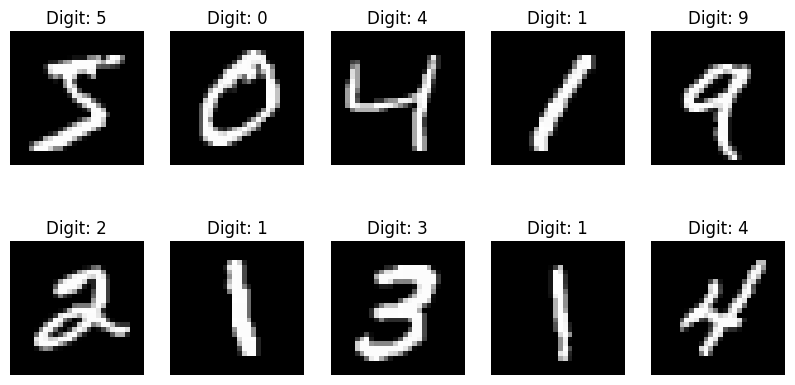

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,762 (120.16 KB)

 Trainable params: 30,762 (120.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.8394 - loss: 0.5562 - val_accuracy: 0.9520 - val_loss: 0.1568
Epoch 2/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9576 - loss: 0.1485 - val_accuracy: 0.9640 - val_loss: 0.1137
Epoch 3/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.9688 - loss: 0.1057 - val_accuracy: 0.9685 - val_loss: 0.0957
Epoch 4/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9723 - loss: 0.0872 - val_accuracy: 0.9745 - val_loss: 0.0866
Epoch 5/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 54ms/step - accuracy: 0.9778 - loss: 0.0692 - val_accuracy: 0.9715 - val_loss: 0.0884

Test Accuracy : 0.9736999869346619
Test Loss     : 0.08287321776151657


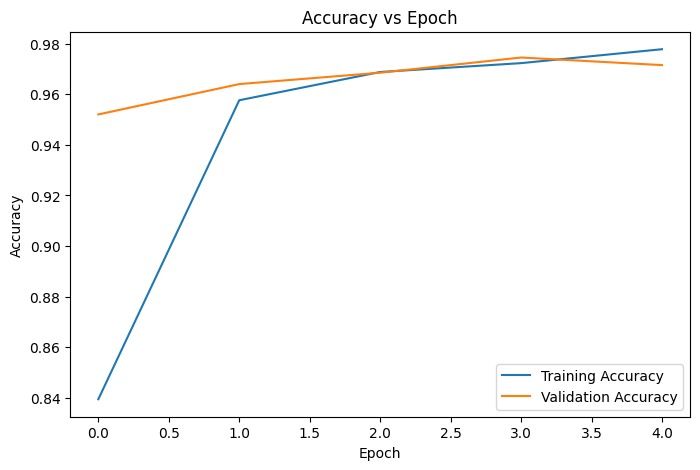

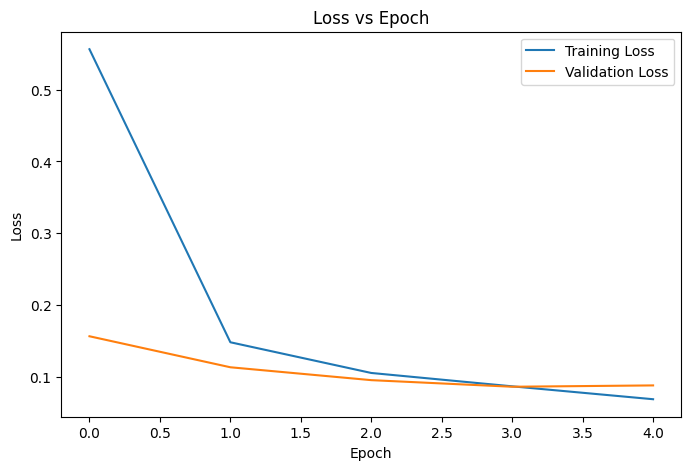

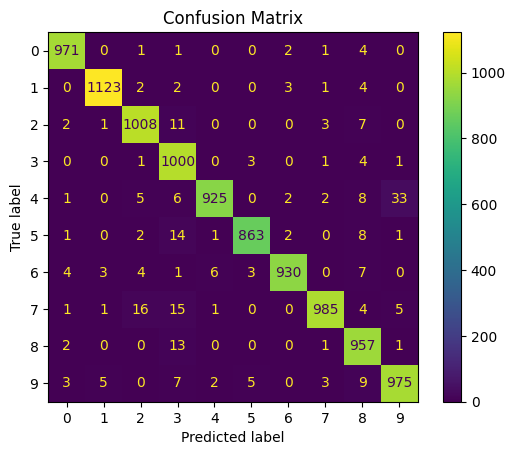

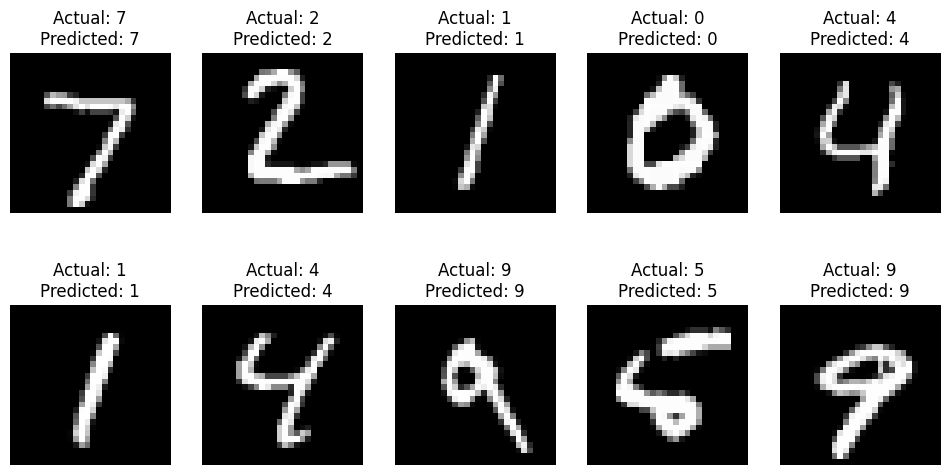

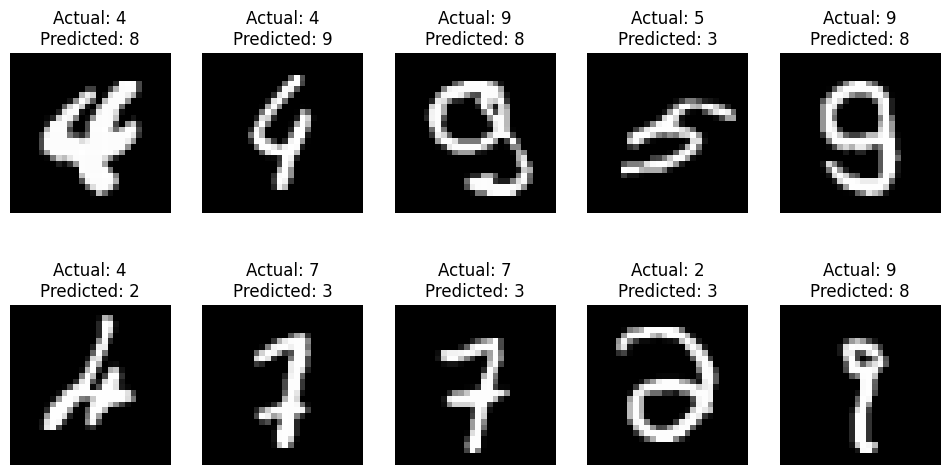

In [2]:
# ============================================================
# Name          : Navithanjali M S
# Roll No       : 24BAD077
# Experiment No : 3
# Title         : Implementation of CNNs for Image Classification
# ============================================================
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = datasets.mnist.load_data()
# Use a smaller training dataset for faster execution
x_train = x_train[:20000]
y_train = y_train[:20000]
# Create validation dataset
x_val = x_train[-2000:]
y_val = y_train[-2000:]
x_train = x_train[:-2000]
y_train = y_train[:-2000]
# Normalize pixel values from 0-255 to 0-1
x_train = x_train / 255.0
x_val = x_val / 255.0
x_test = x_test / 255.0
# Add channel dimension
x_train = x_train[..., np.newaxis]
x_val = x_val[..., np.newaxis]
x_test = x_test[..., np.newaxis]
print("Training Images   :", x_train.shape)
print("Validation Images :", x_val.shape)
print("Testing Images    :", x_test.shape)
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')
plt.show()
# ------------------------------------------------------------
# PART B : CNN MODEL IMPLEMENTATION
# ------------------------------------------------------------
model = models.Sequential()
# Convolution Layer
model.add(layers.Conv2D(
    16,
    (3, 3),
    activation='relu',
    input_shape=(28, 28, 1)
))
# Max Pooling Layer
model.add(layers.MaxPooling2D((2, 2)))
# Second Convolution Layer
model.add(layers.Conv2D(
    32,
    (3, 3),
    activation='relu'
))
# Second Max Pooling Layer
model.add(layers.MaxPooling2D((2, 2)))
# Flatten Layer
model.add(layers.Flatten())
# Fully Connected Layer
model.add(layers.Dense(32, activation='relu'))
# Output Layer - 10 classes
model.add(layers.Dense(10, activation='softmax'))
# Display Model Architecture
model.summary()
# ------------------------------------------------------------
# COMPILE MODEL
# ------------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
# ------------------------------------------------------------
# PART C : MODEL TRAINING
# ------------------------------------------------------------
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val)
)
# ------------------------------------------------------------
# MODEL EVALUATION
# ------------------------------------------------------------
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)
print("\nTest Accuracy :", test_accuracy)
print("Test Loss     :", test_loss)
plt.figure(figsize=(8, 5))
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
# Generate predictions
predictions = model.predict(
    x_test,
    verbose=0
)
# Convert probabilities into predicted classes
predicted_labels = np.argmax(
    predictions,
    axis=1
)
cm = confusion_matrix(
    y_test,
    predicted_labels
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
disp.plot()
plt.title("Confusion Matrix")
plt.show()
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        x_test[i].squeeze(),
        cmap='gray'
    )
    actual = y_test[i]
    predicted = predicted_labels[i]

    plt.title(
        "Actual: " + str(actual) +
        "\nPredicted: " + str(predicted)
    )
    plt.axis('off')

plt.show()
# ------------------------------------------------------------
# MISCLASSIFIED IMAGES
# ------------------------------------------------------------
wrong_indices = np.where(
    predicted_labels != y_test
)[0]
plt.figure(figsize=(12, 6))
for i in range(min(10, len(wrong_indices))):
    index = wrong_indices[i]
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        x_test[index].squeeze(),
        cmap='gray'
    )
    plt.title(
        "Actual: " + str(y_test[index]) +
        "\nPredicted: " + str(predicted_labels[index])
    )
    plt.axis('off')
plt.show()